In [3]:
# import requests
# from bs4 import BeautifulSoup

# def list_directory(url):
#     r = requests.get(url)
#     soup = BeautifulSoup(r.text, "html.parser")
#     links = [a["href"] for a in soup.find_all("a", href=True)
#              if not a["href"].startswith("?") and a["href"] != "/"]
#     return links

# list_directory(f"{BASE_URL}/2_metadata/")

In [1]:
import pandas as pd
from shapely.geometry import Point
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

BASE_URL = "https://catalogue.ceh.ac.uk/datastore/eidchub/211710ac-f01b-4b52-807f-373babb1c368"

# Read a CSV directly — no download needed
df = pd.read_csv(f"{BASE_URL}/2_metadata/2_1_station_identification_metadata/00_station_id_meta.csv")
df.head()

,station_id,River,Location,Start_date,End_date,Missing_values_%,Catchment_Area,Easting,Northing,nrfa_quality_status_v14
0,1001,Wick,Tarroul,09/11/1995 11:15,31/12/2023 23:45,0.00,161.9,326202,954915,Daily
1,2001,Helmsdale,Kilphedir,21/06/1974 09:00,31/12/2023 23:45,0.00,551.4,299839,918163,Pooling
2,2002,Brora,Bruachrobie,01/05/1993 09:00,31/12/2023 23:45,0.00,434.4,289156,903916,Pooling
3,3002,Carron,Sgodachail,13/11/1973 09:15,31/12/2023 23:45,0.04,241.1,249136,892152,Pooling
4,3003,Oykel,Easter Turnaig,11/11/1977 09:00,31/12/2023 23:45,0.00,330.7,240305,900145,Pooling


In [2]:
# Get just the gauge location information
station_locs = df[['station_id', 'River', 'Easting', 'Northing']]
# Construct the geometry from the latitude and longitude using Shapely
geometry = [Point(xy) for xy in zip(df.Easting, df.Northing)]
# Create the geodataframe
# gauge_locs = topography.drop(['gauge_lon', 'gauge_lat'], axis=1)
station_locs_gdf = gpd.GeoDataFrame(station_locs, crs="EPSG:27700", geometry=geometry)
station_locs_gdf.head()

,station_id,River,Easting,Northing,geometry
0,1001,Wick,326202,954915,POINT (326202 954915)
1,2001,Helmsdale,299839,918163,POINT (299839 918163)
2,2002,Brora,289156,903916,POINT (289156 903916)
3,3002,Carron,249136,892152,POINT (249136 892152)
4,3003,Oykel,240305,900145,POINT (240305 900145)


In [3]:
station_locs_3857 = station_locs_gdf.to_crs(epsg=3857)

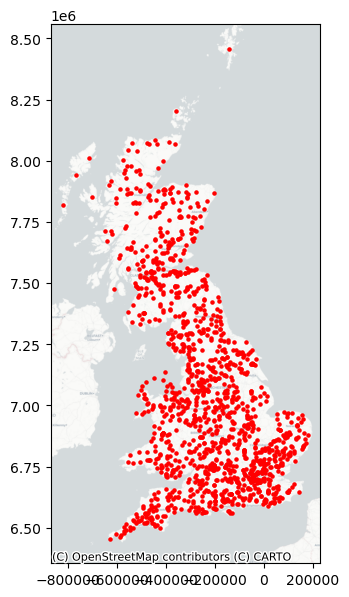

In [4]:
fig,ax=plt.subplots(figsize=(7,7))
station_locs_3857.plot(ax=ax, markersize=5, color="red")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)